In [42]:
SCOPETYPE = 'CWNANO'
PLATFORM = 'CWNANO'
CRYPTO_TARGET='TINYAES128C'
SS_VER='SS_VER_2_1'

In [43]:
%run "../Setup_Scripts/Setup_Generic.ipynb"

INFO: Caught exception on reconnecting to target - attempting to reconnect to scope first.
INFO: This is a work-around when USB has died without Python knowing. Ignore errors above this line.
INFO: Found ChipWhisperer😍


# Compile and Program the Firmware

In [44]:
import os
os.environ["PATH"] = "/Applications/ArmGNUToolchain/14.3.rel1/arm-none-eabi/bin:" + os.environ["PATH"]

In [45]:
import shutil
print(shutil.which("arm-none-eabi-gcc"))

/Applications/ArmGNUToolchain/14.3.rel1/arm-none-eabi/bin/arm-none-eabi-gcc


In [46]:
%%bash -s "$PLATFORM" "$CRYPTO_TARGET" "$SS_VER"
cd ../../firmware/mcu/simpleserial-aes
make PLATFORM=$1 CRYPTO_TARGET=$2 SS_VER=$3 -j

Building for platform CWNANO with CRYPTO_TARGET=TINYAES128C
SS_VER set to SS_VER_2_1
SS_VER set to SS_VER_2_1
Blank crypto options, building for AES128
arm-none-eabi-gcc (Arm GNU Toolchain 14.3.Rel1 (Build arm-14.174)) 14.3.1 20250623
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWNANO 
.
Welcome to another exciting ChipWhisperer target build!!
.
.
.
.
.
.
.
.
Compiling:
Compiling:
Compiling:
Compiling:
Compiling:
Compiling:
Assembling: .././hal//stm32f0/stm32f0_startup.S
-en     .././hal//stm32f0_nano/stm32f0_hal_nano.c ...
arm-none-eabi-gcc -c -mcpu=cortex-m0 -I. -x assembler-with-cpp -mthumb -mfloat-abi=soft -ffunction-sections -DF_CPU=7372800 -Wa,-gstabs,-adhlns=objdir-CWNANO/stm32f0_startup.lst -I.././simpleserial/ -I.././hal/ -I.././hal/ -I.././hal//stm32f0 -I.././hal//stm32f0/CMSIS -I.././hal//stm32f0/CMSIS/c

/Applications/ArmGNUToolchain/14.3.rel1/arm-none-eabi/bin/../lib/gcc/arm-none-eabi/14.3.1/../../../../arm-none-eabi/bin/ld: warning: simpleserial-aes-CWNANO.elf has a LOAD segment with RWX permissions


Memory region         Used Size  Region Size  %age Used
             RAM:        2288 B         4 KB     55.86%
             ROM:        5936 B        32 KB     18.12%
-e Done!
.
.
.
.
.
Creating load file for Flash: simpleserial-aes-CWNANO.hex
Creating load file for EEPROM: simpleserial-aes-CWNANO.eep
arm-none-eabi-objcopy -j .eeprom --set-section-flags=.eeprom="alloc,load" \
	--change-section-lma .eeprom=0 --no-change-warnings -O ihex simpleserial-aes-CWNANO.elf simpleserial-aes-CWNANO.eep || exit 0
Creating load file for Flash: simpleserial-aes-CWNANO.bin
arm-none-eabi-objcopy -O ihex -R .eeprom -R .fuse -R .lock -R .signature simpleserial-aes-CWNANO.elf simpleserial-aes-CWNANO.hex
Creating Extended Listing: simpleserial-aes-CWNANO.lss
arm-none-eabi-objcopy -O binary -R .eeprom -R .fuse -R .lock -R .signature simpleserial-aes-CWNANO.elf simpleserial-aes-CWNANO.bin
arm-none-eabi-objdump -h -S -z simpleserial-aes-CWNANO.elf > simpleserial-aes-CWNANO.lss
Creating Symbol Table: simplese

In [47]:
cw.program_target(scope, prog, "../../firmware/mcu/simpleserial-aes/simpleserial-aes-{}.hex".format(PLATFORM))

Detected known STMF32: STM32F03xx4/03xx6
Extended erase (0x44), this can take ten seconds or more
Attempting to program 5935 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 5935 bytes


# Get Traces

以下原碼
import chipwhisperer as cw
from tqdm.notebook import trange
import numpy as np
import time

ktp = cw.ktp.Basic()
trace_array = []
textin_array = []

key, text = ktp.next()

target.set_key(key)

N = 500

for i in trange(N, desc='Capturing traces'):
    scope.arm()
    
    target.simpleserial_write('p', text)
    
    ret = scope.capture()
    if ret:
        print("Target timed out!")
        continue
    
    response = target.simpleserial_read('r', 16)
    
    trace_array.append(scope.get_last_trace())
    textin_array.append(text)
    
    key, text = ktp.next()
    
traces = np.array(trace_array)
plaintexts = np.array(textin_array, dtype=np.uint8)
key = np.array(key, dtype=np.uint8)

In [48]:
import chipwhisperer as cw
import numpy as np
from tqdm.notebook import tqdm
from pathlib import Path

TOTAL = 51200
BATCH_SIZE = 1000
SAVE_DIR = Path("aes128_batches")
SAVE_DIR.mkdir(exist_ok=True)

ktp = cw.ktp.Basic()
used_plaintexts = set()
saved_count = 0
batch_index = 0
saved_key = None

for file in sorted(SAVE_DIR.glob("batch_*.npz")):
    with np.load(file) as data:
        saved_count += len(data["p"])
        used_plaintexts.update(bytes(p) for p in data["p"])
        existing_key = data["k"].copy()

        if saved_key is None:
            saved_key = existing_key
        elif not np.array_equal(saved_key, existing_key):
            raise ValueError("已儲存批次的金鑰不一致")

    batch_index += 1

if saved_key is None:
    first_key, _ = ktp.next()
    saved_key = np.array(first_key, dtype=np.uint8)

target.set_key(saved_key.tolist())

print(f"已完成：{saved_count}/{TOTAL}")

with tqdm(total=TOTAL, initial=saved_count, desc="Capturing traces") as progress:
    while saved_count < TOTAL:
        batch_traces = []
        batch_plaintexts = []
        count = min(BATCH_SIZE, TOTAL - saved_count)

        while len(batch_traces) < count:
            _, text = ktp.next()
            text = np.array(text, dtype=np.uint8)

            if bytes(text) in used_plaintexts:
                continue

            scope.arm()
            target.simpleserial_write("p", text.tolist())

            if scope.capture():
                print("Target timed out, retrying...")
                continue

            target.simpleserial_read("r", 16)

            batch_traces.append(
                np.array(scope.get_last_trace(), dtype=np.float32)
            )
            batch_plaintexts.append(text)
            used_plaintexts.add(bytes(text))
            progress.update(1)

        filename = SAVE_DIR / f"batch_{batch_index:04d}.npz"

        np.savez(
            filename,
            t=np.array(batch_traces, dtype=np.float32),
            p=np.array(batch_plaintexts, dtype=np.uint8),
            k=saved_key
        )

        saved_count += len(batch_traces)
        batch_index += 1

        print(f"已儲存：{filename}，累計 {saved_count} 條")

print("擷取完成！")

已完成：0/51200


Capturing traces:   0%|          | 0/51200 [00:00<?, ?it/s]

已儲存：aes128_batches/batch_0000.npz，累計 1000 條
已儲存：aes128_batches/batch_0001.npz，累計 2000 條
已儲存：aes128_batches/batch_0002.npz，累計 3000 條
已儲存：aes128_batches/batch_0003.npz，累計 4000 條
已儲存：aes128_batches/batch_0004.npz，累計 5000 條
已儲存：aes128_batches/batch_0005.npz，累計 6000 條
已儲存：aes128_batches/batch_0006.npz，累計 7000 條
已儲存：aes128_batches/batch_0007.npz，累計 8000 條
已儲存：aes128_batches/batch_0008.npz，累計 9000 條
已儲存：aes128_batches/batch_0009.npz，累計 10000 條
已儲存：aes128_batches/batch_0010.npz，累計 11000 條
已儲存：aes128_batches/batch_0011.npz，累計 12000 條
已儲存：aes128_batches/batch_0012.npz，累計 13000 條
已儲存：aes128_batches/batch_0013.npz，累計 14000 條
已儲存：aes128_batches/batch_0014.npz，累計 15000 條
已儲存：aes128_batches/batch_0015.npz，累計 16000 條
已儲存：aes128_batches/batch_0016.npz，累計 17000 條
已儲存：aes128_batches/batch_0017.npz，累計 18000 條
已儲存：aes128_batches/batch_0018.npz，累計 19000 條
已儲存：aes128_batches/batch_0019.npz，累計 20000 條
已儲存：aes128_batches/batch_0020.npz，累計 21000 條
已儲存：aes128_batches/batch_0021.npz，累計 22000 條
已儲存：aes128_batches/

In [51]:
import numpy as np
from pathlib import Path

batch_files = sorted(Path("aes128_batches").glob("batch_*.npz"))

print("批次檔案數量：", len(batch_files))

all_traces = []
all_plaintexts = []

for file in batch_files:
    with np.load(file) as data:
        print(file.name, data.files)
        break

批次檔案數量： 52
batch_0000.npz ['t', 'p', 'k']


In [52]:
import numpy as np
from pathlib import Path

batch_files = sorted(Path("aes128_batches").glob("batch_*.npz"))

all_traces = []
all_plaintexts = []
all_keys = []

for file in batch_files:
    with np.load(file) as data:
        all_traces.append(data["t"])
        all_plaintexts.append(data["p"])
        all_keys.append(data["k"])

traces = np.concatenate(all_traces, axis=0)
plaintexts = np.concatenate(all_plaintexts, axis=0)

keys = np.concatenate([
    k.reshape(1, -1) if k.ndim == 1 else k
    for k in all_keys
], axis=0)

key = keys[0]

print("Traces:", traces.shape)
print("Plaintexts:", plaintexts.shape)
print("Key:", key)
print("所有金鑰相同：", np.all(keys == key))

Traces: (51200, 5000)
Plaintexts: (51200, 16)
Key: [ 43 126  21  22  40 174 210 166 171 247  21 136   9 207  79  60]
所有金鑰相同： True


In [53]:
print(traces.shape)
print(plaintexts.shape)
print(key)

(51200, 5000)
(51200, 16)
[ 43 126  21  22  40 174 210 166 171 247  21 136   9 207  79  60]


In [54]:
unique_plaintexts = np.unique(plaintexts, axis=0)

print("總數：", len(plaintexts))
print("不重複數量：", len(unique_plaintexts))
print("重複數量：", len(plaintexts) - len(unique_plaintexts))

總數： 51200
不重複數量： 51200
重複數量： 0


# Save traces to an npz file
np.savez('cwnano_aes128_traces', t=traces, p=plaintexts, k=key)

In [55]:
# Load traces from the saved npz file
data = np.load('cwnano_aes128_traces.npz')
print(data['k'])
print(data['p'])

[ 43 126  21  22  40 174 210 166 171 247  21 136   9 207  79  60]
[[ 37 183  54 ... 116  50  43]
 [145  69  66 ...  81 100 117]
 [177  60  69 ... 135 249  47]
 ...
 [ 85  25  63 ... 227 251  71]
 [ 60  88 159 ... 228 169 150]
 [207  68 168 ...  27 142 212]]


In [56]:
scope.dis()
target.dis()

In [57]:
# The AES SBox that we will use to generate our labels
AES_Sbox = np.array([
            0x63, 0x7C, 0x77, 0x7B, 0xF2, 0x6B, 0x6F, 0xC5, 0x30, 0x01, 0x67, 0x2B, 0xFE, 0xD7, 0xAB, 0x76,
            0xCA, 0x82, 0xC9, 0x7D, 0xFA, 0x59, 0x47, 0xF0, 0xAD, 0xD4, 0xA2, 0xAF, 0x9C, 0xA4, 0x72, 0xC0,
            0xB7, 0xFD, 0x93, 0x26, 0x36, 0x3F, 0xF7, 0xCC, 0x34, 0xA5, 0xE5, 0xF1, 0x71, 0xD8, 0x31, 0x15,
            0x04, 0xC7, 0x23, 0xC3, 0x18, 0x96, 0x05, 0x9A, 0x07, 0x12, 0x80, 0xE2, 0xEB, 0x27, 0xB2, 0x75,
            0x09, 0x83, 0x2C, 0x1A, 0x1B, 0x6E, 0x5A, 0xA0, 0x52, 0x3B, 0xD6, 0xB3, 0x29, 0xE3, 0x2F, 0x84,
            0x53, 0xD1, 0x00, 0xED, 0x20, 0xFC, 0xB1, 0x5B, 0x6A, 0xCB, 0xBE, 0x39, 0x4A, 0x4C, 0x58, 0xCF,
            0xD0, 0xEF, 0xAA, 0xFB, 0x43, 0x4D, 0x33, 0x85, 0x45, 0xF9, 0x02, 0x7F, 0x50, 0x3C, 0x9F, 0xA8,
            0x51, 0xA3, 0x40, 0x8F, 0x92, 0x9D, 0x38, 0xF5, 0xBC, 0xB6, 0xDA, 0x21, 0x10, 0xFF, 0xF3, 0xD2,
            0xCD, 0x0C, 0x13, 0xEC, 0x5F, 0x97, 0x44, 0x17, 0xC4, 0xA7, 0x7E, 0x3D, 0x64, 0x5D, 0x19, 0x73,
            0x60, 0x81, 0x4F, 0xDC, 0x22, 0x2A, 0x90, 0x88, 0x46, 0xEE, 0xB8, 0x14, 0xDE, 0x5E, 0x0B, 0xDB,
            0xE0, 0x32, 0x3A, 0x0A, 0x49, 0x06, 0x24, 0x5C, 0xC2, 0xD3, 0xAC, 0x62, 0x91, 0x95, 0xE4, 0x79,
            0xE7, 0xC8, 0x37, 0x6D, 0x8D, 0xD5, 0x4E, 0xA9, 0x6C, 0x56, 0xF4, 0xEA, 0x65, 0x7A, 0xAE, 0x08,
            0xBA, 0x78, 0x25, 0x2E, 0x1C, 0xA6, 0xB4, 0xC6, 0xE8, 0xDD, 0x74, 0x1F, 0x4B, 0xBD, 0x8B, 0x8A,
            0x70, 0x3E, 0xB5, 0x66, 0x48, 0x03, 0xF6, 0x0E, 0x61, 0x35, 0x57, 0xB9, 0x86, 0xC1, 0x1D, 0x9E,
            0xE1, 0xF8, 0x98, 0x11, 0x69, 0xD9, 0x8E, 0x94, 0x9B, 0x1E, 0x87, 0xE9, 0xCE, 0x55, 0x28, 0xDF,
            0x8C, 0xA1, 0x89, 0x0D, 0xBF, 0xE6, 0x42, 0x68, 0x41, 0x99, 0x2D, 0x0F, 0xB0, 0x54, 0xBB, 0x16
            ])
# The Hamming weight list of each byte value
hw_list = np.array([
            0, 1, 1, 2, 1, 2, 2, 3, 1, 2, 2, 3, 2, 3, 3, 4, 1, 2, 2, 3, 2, 3, 3, 4, 2, 3, 3, 4, 3, 4, 4, 5, 
            1, 2, 2, 3, 2, 3, 3, 4, 2, 3, 3, 4, 3, 4, 4, 5, 2, 3, 3, 4, 3, 4, 4, 5, 3, 4, 4, 5, 4, 5, 5, 6, 
            1, 2, 2, 3, 2, 3, 3, 4, 2, 3, 3, 4, 3, 4, 4, 5, 2, 3, 3, 4, 3, 4, 4, 5, 3, 4, 4, 5, 4, 5, 5, 6, 
            2, 3, 3, 4, 3, 4, 4, 5, 3, 4, 4, 5, 4, 5, 5, 6, 3, 4, 4, 5, 4, 5, 5, 6, 4, 5, 5, 6, 5, 6, 6, 7, 
            1, 2, 2, 3, 2, 3, 3, 4, 2, 3, 3, 4, 3, 4, 4, 5, 2, 3, 3, 4, 3, 4, 4, 5, 3, 4, 4, 5, 4, 5, 5, 6,
            2, 3, 3, 4, 3, 4, 4, 5, 3, 4, 4, 5, 4, 5, 5, 6, 3, 4, 4, 5, 4, 5, 5, 6, 4, 5, 5, 6, 5, 6, 6, 7,
            2, 3, 3, 4, 3, 4, 4, 5, 3, 4, 4, 5, 4, 5, 5, 6, 3, 4, 4, 5, 4, 5, 5, 6, 4, 5, 5, 6, 5, 6, 6, 7,
            3, 4, 4, 5, 4, 5, 5, 6, 4, 5, 5, 6, 5, 6, 6, 7, 4, 5, 5, 6, 5, 6, 6, 7, 5, 6, 6, 7, 6, 7, 7, 8
            ])

In [58]:
p = data['p']
k = data['k']
h = hw_list[AES_Sbox[p^k]]


In [59]:
t = data['t']
print(t[0])

[-0.30078125 -0.0078125  -0.0859375  ... -0.078125   -0.11328125
 -0.3203125 ]


In [60]:
print(t[h[:,0] == 4])

[[-0.12109375  0.00390625 -0.1015625  ... -0.07421875 -0.11328125
  -0.31640625]
 [-0.12890625 -0.01953125 -0.1015625  ... -0.06640625 -0.11328125
  -0.3046875 ]
 [-0.12109375  0.         -0.09765625 ... -0.0703125  -0.109375
  -0.3203125 ]
 ...
 [-0.10546875 -0.00390625 -0.078125   ... -0.06640625 -0.1015625
  -0.296875  ]
 [-0.3046875  -0.00390625 -0.08203125 ... -0.078125   -0.1015625
  -0.3046875 ]
 [-0.1015625  -0.00390625 -0.078125   ... -0.0703125  -0.1015625
  -0.296875  ]]


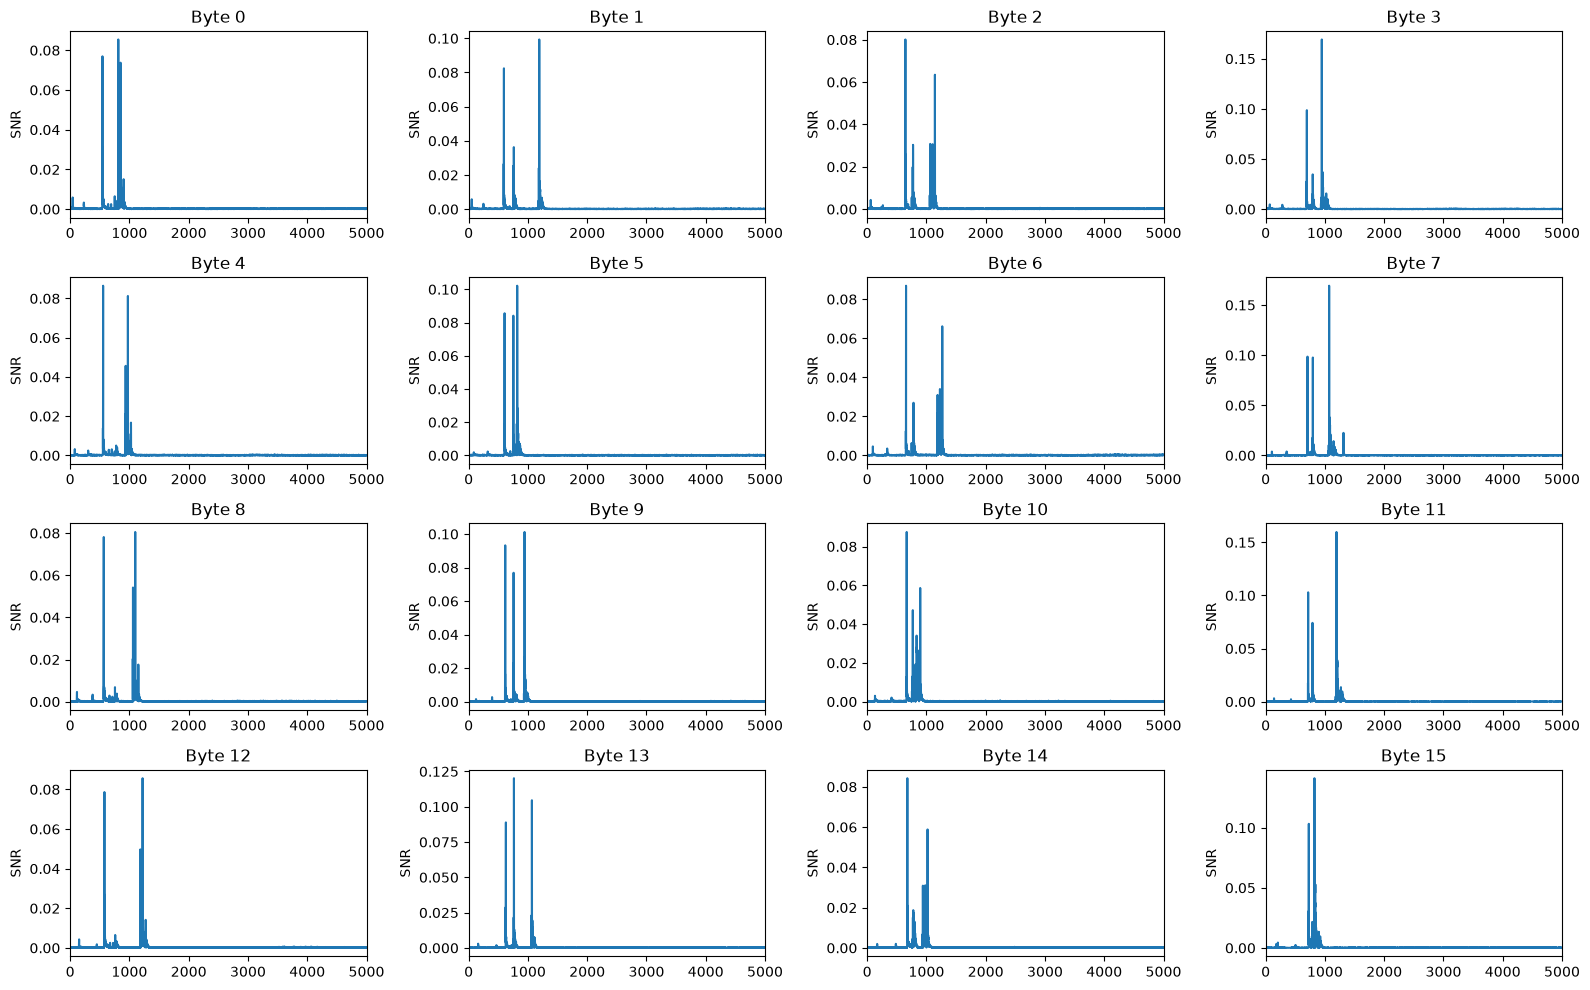

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from chipwhisperer.analyzer.attacks.models.aes.funcs import sbox

def hamming_weight(x):
    return int(x).bit_count()

def calculate_snr(traces, labels):
    traces = np.asarray(traces, dtype=np.float64)
    labels = np.asarray(labels)

    means = []
    variances = []
    counts = []

    for hw in range(9):
        group = traces[labels == hw]

        if len(group) < 2:
            continue

        means.append(np.mean(group, axis=0))
        variances.append(np.var(group, axis=0))
        counts.append(len(group))

    means = np.array(means)
    variances = np.array(variances)
    weights = np.array(counts) / np.sum(counts)

    overall_mean = np.average(means, axis=0, weights=weights)
    signal = np.average((means - overall_mean) ** 2, axis=0, weights=weights)
    noise = np.average(variances, axis=0, weights=weights)

    return np.divide(signal, noise, out=np.zeros_like(signal), where=noise > 0)

fig, axes = plt.subplots(4, 4, figsize=(16, 10))

for byte in range(16):
    hw_labels = np.array([
        hamming_weight(sbox(int(p[byte]) ^ int(key[byte])))
        for p in plaintexts
    ])

    snr = calculate_snr(traces, hw_labels)

    ax = axes.flat[byte]
    ax.plot(snr)
    ax.set_title(f"Byte {byte}")
    ax.set_ylabel("SNR")
    ax.set_xlim(0, traces.shape[1])

plt.tight_layout()
plt.show()

In [ ]:
import shutil

print("剩餘硬碟空間：", round(shutil.disk_usage(".").free / 1024**3, 2), "GB")
print("Trace 資料型別：", traces.dtype)

剩餘硬碟空間： 33.21 GB
Trace 資料型別： float32


In [63]:
scope.dis()

True